# CNN – Fruit and Vegetable Classification

## 1. Project Description

### Purpose

We aim to build and train a Convolutional Neural Network (CNN) to classify images of nine different fruits and vegetables.

The goal is to investigate how accurately a CNN can recognize and classify these images and compare its performance with the group's baseline model, which uses Logistic Regression.

### Method

We use the group's existing dataset and the predefined training, validation, and test splits.

The CNN model will learn visual features directly from the images, such as colors, shapes, and textures.

We evaluate the model using accuracy, macro-F1 score, and a confusion matrix.

## 2. Preparation

### 2.1 Import Libraries and Functions

We begin by setting up the Python environment and importing the group's shared functions.

The `load_image()` function is used to load and preprocess the images, while `evaluate_predictions()` will be used later to evaluate the model's performance.

By reusing these functions, we avoid duplicating previous work and ensure a consistent comparison between our CNN and the baseline model.

In [1]:

# Standard Python libraries
import sys                       # Access Python settings and module paths
from pathlib import Path        # Work with file and folder paths

# Data analysis and visualization
import pandas as pd             # Load and analyze datasets
import matplotlib.pyplot as plt # Create plots and visualize images

# PyTorch - Deep Learning
import torch                    # Main PyTorch library
import torch.nn as nn           # Neural network layers and functions
import torch.optim as optim     # Optimization algorithms
from torch.utils.data import Dataset, DataLoader  # Handle image datasets and batches

# Find the project's root directory
project_root = Path.cwd().resolve()

# Move one level up if the notebook runs from the notebooks folder
if project_root.name == "notebooks":
    project_root = project_root.parent

# Add the project directory to Python's module search path
sys.path.insert(0, str(project_root))

# Import shared functions from the group project
from src.preprocess import load_image
from src.evaluate import evaluate_predictions

# Verify the environment
print("Python version:", sys.version.split()[0])
print("PyTorch version:", torch.__version__)
print("Project directory:", project_root)
print("All imports successful!")


Python version: 3.14.6
PyTorch version: 2.15.0
Project directory: /Users/annadontchev/GruppArbeteML/group-project
All imports successful!


## 3. Load and inspect the dataset

### 3.1 Load the existing train, validation and test split

We use the dataset split previously created by Jessica to ensure that all models are trained and evaluated on the same images.

The CSV file contains the image paths, target classes and dataset split assignments.

We first inspect the data to verify the number of images in each split and the available classes before loading the images for our CNN. 

In [ ]:

# Load the existing dataset split
csv_path = project_root / "data" / "dataset_split.csv"
df = pd.read_csv(csv_path)

# Display the first five rows
display(df.head())

# Check the number of images in each split
print("\nImages per split:")
print(df["split"].value_counts())

# Check the available classes
print("\nClasses:")
print(sorted(df["target_class"].unique()))

# Check the total number of images
print("\nTotal images:", len(df))

,image_path,target_class,split
0,data/raw_images/fuji_apple/fuji_apple_002.jpg,apple,test
1,data/raw_images/fuji_apple/fuji_apple_023.jpg,apple,test
2,data/raw_images/fuji_apple/fuji_apple_046.jpg,apple,test
3,data/raw_images/fuji_apple/fuji_apple_053.jpg,apple,test
4,data/raw_images/fuji_apple/fuji_apple_061.jpg,apple,test



Images per split:
split
train         1603
test           200
validation     200
Name: count, dtype: int64

Classes:
['apple', 'honneydew_melon', 'kiwi', 'nectarine', 'onion', 'plum', 'potato', 'spanish_pear', 'watermelon']

Total images: 2003


### 3.2 Load and preprocess images

We use the group's existing `load_image()` function to load and preprocess the images.

Before preparing the images for the CNN, we visualize six training images to check that they are loaded correctly.

We also check the image dimensions and pixel values.

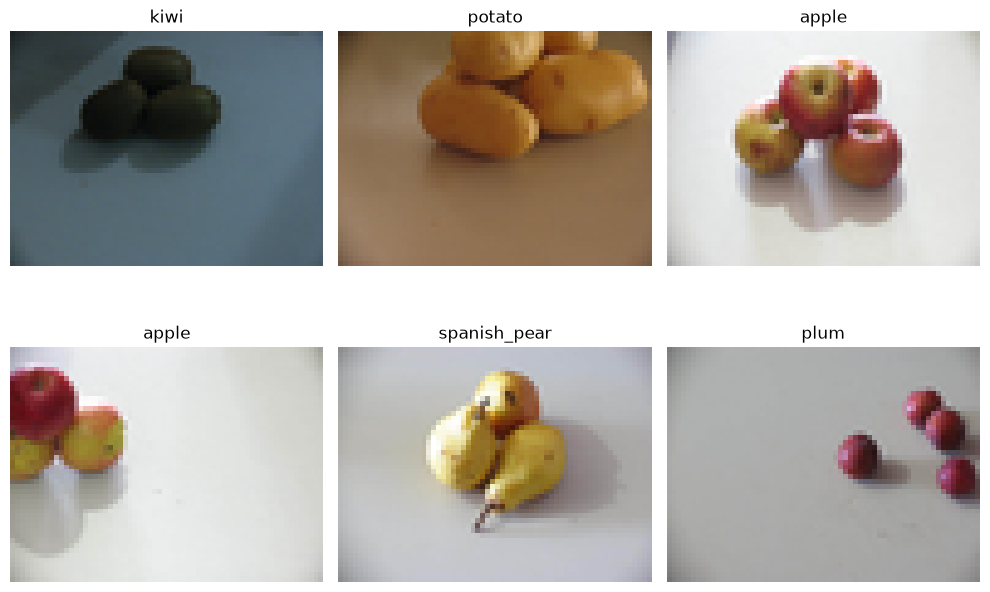

Image shape: (48, 64, 3)
Pixel range: 0.0627451 to 0.8666667


In [ ]:

# Välj sex bilder från träningsdatan
train_df = df[df["split"] == "train"]
sample = train_df.sample(n=6, random_state=42)

# Visa bilderna i ett rutnät
fig, axes = plt.subplots(2, 3, figsize=(10, 7))

for ax, (_, row) in zip(axes.flat, sample.iterrows()):
    image_path = project_root / row["image_path"]
    image = load_image(image_path)

    ax.imshow(image)
    ax.set_title(row["target_class"])
    ax.axis("off")

plt.tight_layout()
plt.show()

# Kontrollera bildformat och pixelvärden
print("Image shape:", image.shape)
print("Pixel range:", image.min(), "to", image.max())

#### Label encoding

We convert the fruit class names into numerical labels (0–8), since PyTorch requires numerical labels for classification.

The same mapping will be used for training, validation and test data.

In [4]:
# Skapa ett nummer för varje fruktklass
class_names = sorted(train_df["target_class"].unique())
class_to_idx = {name: idx for idx, name in enumerate(class_names)}

print("Number of classes:", len(class_names))
print("Class mapping:", class_to_idx)

Number of classes: 9
Class mapping: {'apple': 0, 'honneydew_melon': 1, 'kiwi': 2, 'nectarine': 3, 'onion': 4, 'plum': 5, 'potato': 6, 'spanish_pear': 7, 'watermelon': 8}


#### Create a PyTorch Dataset

We create a custom PyTorch Dataset using the group's existing `load_image()` function.

The images are converted into tensors in the format required by PyTorch (channels, height, width). Each image is paired with its numerical class label.

In [ ]:
class FruitDataset(Dataset):
    def __init__(self, dataframe, project_root, class_to_idx):
        self.dataframe = dataframe.reset_index(drop=True)
        self.project_root = project_root
        self.class_to_idx = class_to_idx

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):
        row = self.dataframe.iloc[idx]

        # Läs in bilden med gruppens befintliga funktion
        image_path = self.project_root / row["image_path"]
        image = load_image(image_path)

        # Ändra från (höjd, bredd, kanaler) till (kanaler, höjd, bredd)
        image = torch.from_numpy(image).permute(2, 0, 1)

        # Koppla bilden till rätt fruktklass
        label = self.class_to_idx[row["target_class"]]
        label = torch.tensor(label, dtype=torch.long)

        return image, label

#### Create DataLoaders

We create datasets for training and validation using our custom `FruitDataset` class.

We use DataLoaders to process the images in batches of 32. Training data is shuffled, while validation data keeps its original order.

The test data will only be used for final evaluation.

In [ ]:
# Använd gruppens befintliga uppdelning
val_df = df[df["split"] == "validation"]

# Skapa Dataset
train_dataset = FruitDataset(train_df, project_root, class_to_idx)
val_dataset = FruitDataset(val_df, project_root, class_to_idx)

# Skapa DataLoader
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)

print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))

Training images: 1603
Validation images: 200


### 3.4 Build the CNN model

We build a Convolutional Neural Network (CNN) using PyTorch to classify the nine fruit classes.

The model uses convolutional layers to learn patterns in the images, ReLU activation functions and max pooling to reduce image dimensions.

The final fully connected layer predicts one of the nine fruit classes.

In [ ]:
class FruitCNN(nn.Module):
    def __init__(self, num_classes=9):
        super().__init__()

        # Extract features from images
        self.features = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        # Classify images into fruit classes
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * 12 * 16, 128),
            nn.ReLU(),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

# Create the CNN model
model = FruitCNN(num_classes=len(class_names))
print(model)

FruitCNN(
  (features): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=6144, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=9, bias=True)
  )
)


### 3.5 Configure model training

We use CrossEntropyLoss to measure how well the model predicts the correct fruit classes.

We use the Adam optimizer to update the model's weights during training, with a learning rate of 0.001.

The model will run on a GPU if available, otherwise on the CPU.

In [ ]:
# Select GPU if available, otherwise use CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)

# Define loss function and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

print("Device:", device)
print("Loss function:", criterion)
print("Optimizer:", optimizer.__class__.__name__)

Device: cpu
Loss function: CrossEntropyLoss()
Optimizer: Adam


### 3.6 Train the CNN model

We train the CNN for 10 epochs using the training dataset.

After each epoch, we evaluate the model on the validation dataset without updating its weights.

We record training and validation loss and accuracy to visualize the model's learning progress and identify possible overfitting.

In [11]:
num_epochs = 10

train_losses = []
val_losses = []
train_accuracies = []
val_accuracies = []

for epoch in range(num_epochs):

    # Training
    model.train()
    running_loss = 0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        predictions = outputs.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    train_loss = running_loss / total
    train_accuracy = correct / total

    # Validation
    model.eval()
    running_val_loss = 0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            running_val_loss += loss.item() * images.size(0)
            predictions = outputs.argmax(dim=1)
            val_correct += (predictions == labels).sum().item()
            val_total += labels.size(0)

    val_loss = running_val_loss / val_total
    val_accuracy = val_correct / val_total

    # Save metrics for visualization
    train_losses.append(train_loss)
    val_losses.append(val_loss)
    train_accuracies.append(train_accuracy)
    val_accuracies.append(val_accuracy)

    print(
        f"Epoch {epoch+1}/{num_epochs} | "
        f"Train loss: {train_loss:.4f} | "
        f"Val loss: {val_loss:.4f} | "
        f"Train accuracy: {train_accuracy:.2%} | "
        f"Val accuracy: {val_accuracy:.2%}"
    )

Epoch 1/10 | Train loss: 1.6920 | Val loss: 0.9922 | Train accuracy: 43.04% | Val accuracy: 75.50%
Epoch 2/10 | Train loss: 0.7504 | Val loss: 0.6622 | Train accuracy: 76.29% | Val accuracy: 78.00%
Epoch 3/10 | Train loss: 0.4689 | Val loss: 0.5302 | Train accuracy: 84.03% | Val accuracy: 83.00%
Epoch 4/10 | Train loss: 0.3221 | Val loss: 0.3020 | Train accuracy: 89.58% | Val accuracy: 92.00%
Epoch 5/10 | Train loss: 0.2372 | Val loss: 0.2949 | Train accuracy: 91.39% | Val accuracy: 90.00%
Epoch 6/10 | Train loss: 0.1778 | Val loss: 0.2010 | Train accuracy: 94.88% | Val accuracy: 94.00%
Epoch 7/10 | Train loss: 0.1582 | Val loss: 0.2031 | Train accuracy: 94.82% | Val accuracy: 93.50%
Epoch 8/10 | Train loss: 0.1749 | Val loss: 0.1777 | Train accuracy: 94.88% | Val accuracy: 95.00%
Epoch 9/10 | Train loss: 0.1445 | Val loss: 0.2166 | Train accuracy: 95.38% | Val accuracy: 92.00%
Epoch 10/10 | Train loss: 0.1074 | Val loss: 0.1490 | Train accuracy: 96.76% | Val accuracy: 93.50%


### 3.7 Visualize training results

We visualize training and validation loss and accuracy across the 10 epochs.

These plots help us understand how well the CNN learns and identify signs of overfitting.

We use the validation results to evaluate whether the model needs further improvements.

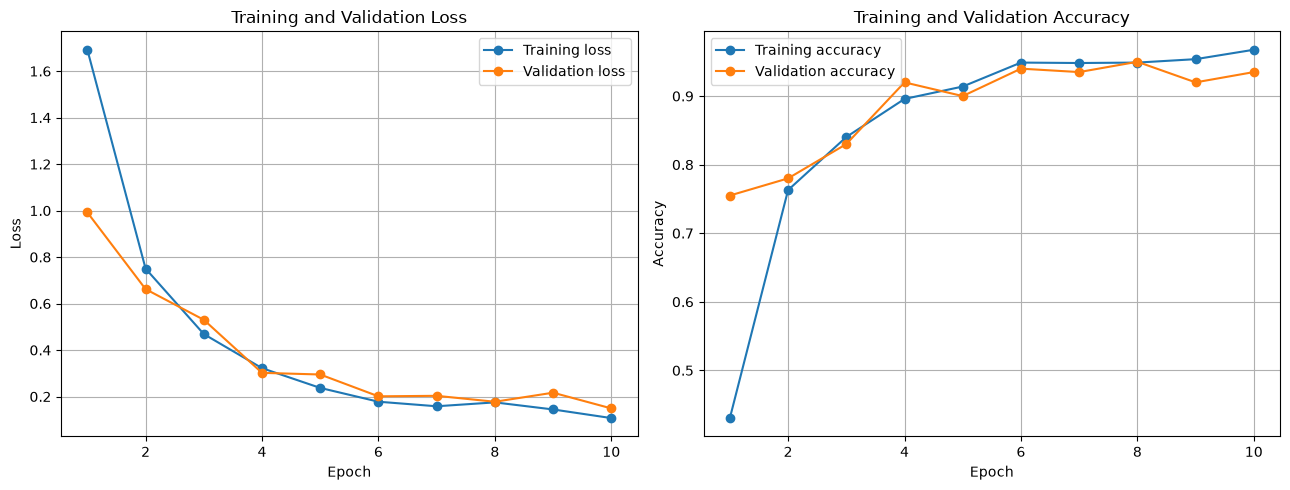

In [ ]:
epochs = range(1, num_epochs + 1)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Plot training and validation loss
axes[0].plot(epochs, train_losses, label="Training loss", marker="o")
axes[0].plot(epochs, val_losses, label="Validation loss", marker="o")
axes[0].set_title("Training and Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True)

# Plot training and validation accuracy
axes[1].plot(epochs, train_accuracies, label="Training accuracy", marker="o")
axes[1].plot(epochs, val_accuracies, label="Validation accuracy", marker="o")
axes[1].set_title("Training and Validation Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

#### Analysis of training results

Both training and validation loss decrease during training, which shows that the model is learning.

Accuracy improves quickly during the first epochs and then starts to stabilize. The highest validation accuracy is 95% at epoch 8, while training accuracy reaches 96.76% at epoch 10.

There is a small difference between training and validation accuracy, but no clear signs of serious overfitting.

Overall, the CNN performs well. The next step is to investigate which fruit classes the model has difficulty predicting.